In [2]:
import pandas as pd
import seaborn as sns 
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('~/MinaRyten/Melissa/teamWood/ClusterProfiler/07-clusterProfiler_res_logfc1.csv')

In [4]:
OGs = df[(df['assay'].str.contains('OG'))]

terms = ['myelin','Myelin', 'myelination','Myelination', 'Wnt', 'lymphocyte', 'leukocyte', 'mononuclear', 'B cell', 'T cell']
pattern = '|'.join(terms)  # creates 'CSF|plasma|serum'

filtered_OGs = OGs[OGs['Description'].str.contains(pattern, case=False, na=False)]
#filtered_OGs.to_csv('processed_data/peripheral_immune_pathways_OGs.csv')


/tmp/ipykernel_334065/1769582476.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plotting['GeneRatio'] = plotting['GeneRatio'].str.split('/', expand = True)[0].astype(int)/plotting['GeneRatio'].str.split('/', expand = True)[1].astype(int)


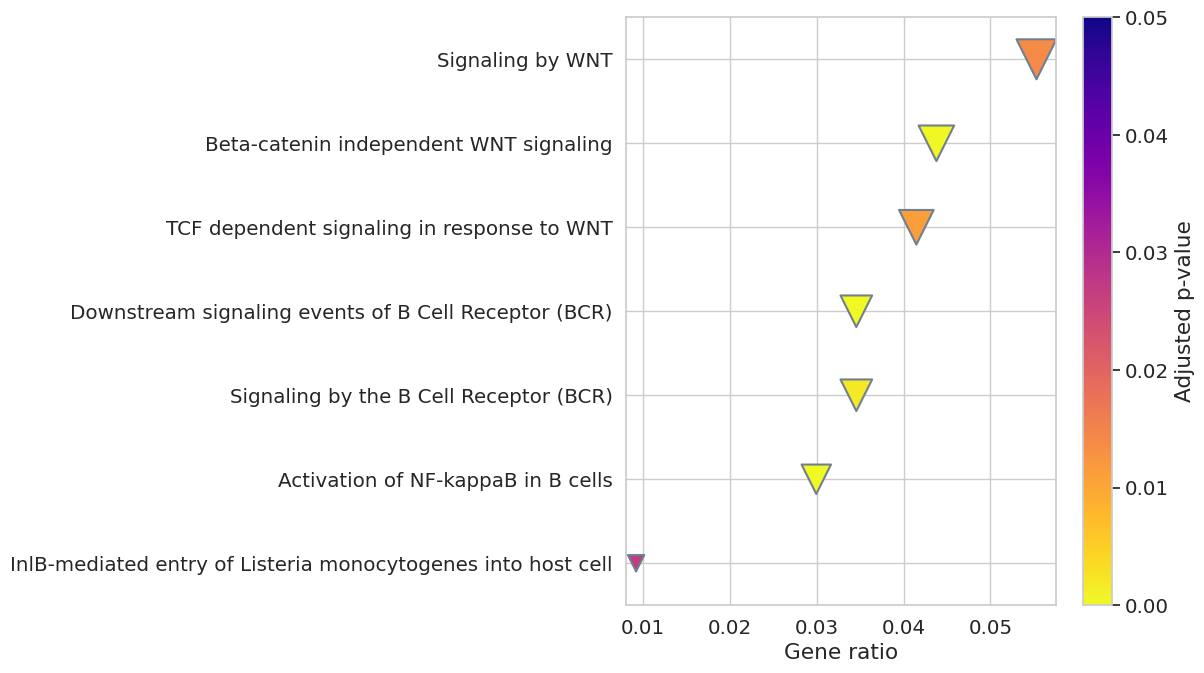

In [5]:
sns.set(font_scale = 1.3, style = "whitegrid")

filtered_OGs = filtered_OGs[filtered_OGs['tissue']=='F']
plotting = filtered_OGs[filtered_OGs['annot_level']==1]

plotting['GeneRatio'] = plotting['GeneRatio'].str.split('/', expand = True)[0].astype(int)/plotting['GeneRatio'].str.split('/', expand = True)[1].astype(int)

plotting = plotting.sort_values('GeneRatio', ascending = False)
sns.set_style("whitegrid")

# Normalize p.adjust values
norm = mcolors.Normalize(vmin=0, vmax=0.05)
cmap = cm.plasma_r
colors = [cmap(norm(val)) for val in plotting["p.adjust"]]

# Scale GeneRatio for triangle size
size_scale = 15000
sizes = plotting["GeneRatio"] * size_scale

# Create the plot
fig, ax = plt.subplots(figsize=(12, 7))
# Expand borders to fit triangles
ax.set_ylim(-0.5, len(plotting["Description"]) - 0.5)
ax.set_xlim(plotting["GeneRatio"].min() * 0.87, plotting["GeneRatio"].max() * 1.04)

# Actually plot
sns.scatterplot(
    x=plotting["GeneRatio"],
    y=plotting["Description"],
    s=sizes,
    marker="v",  # downward-facing triangle
    color=colors,  # prevent default fill
    edgecolor='slategrey',
    linewidth=1.5,
    ax=ax
)

# Add colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Adjusted p-value")

# Fix labels
ax.set_xlabel("Gene ratio")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig('')
plt.show()

/tmp/ipykernel_334065/322315940.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plotting['GeneRatio'] = plotting['GeneRatio'].str.split('/', expand = True)[0].astype(int)/plotting['GeneRatio'].str.split('/', expand = True)[1].astype(int)


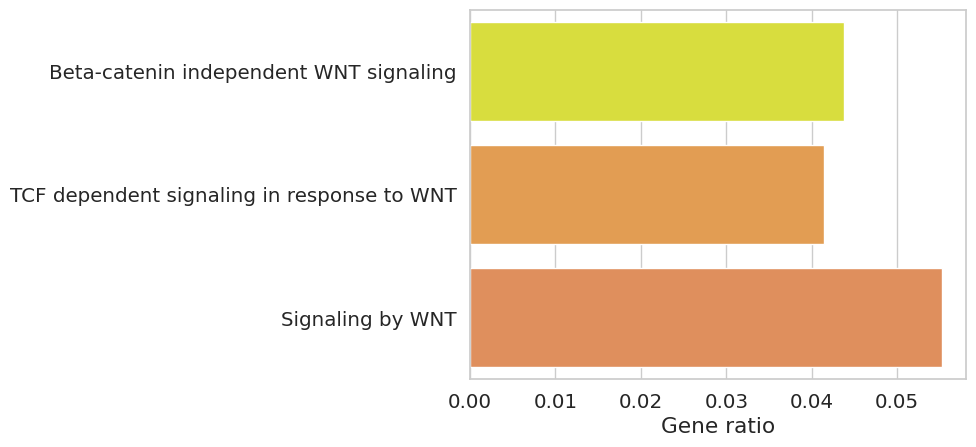

In [6]:
terms = ['Wnt']
pattern = '|'.join(terms)  # creates 'CSF|plasma|serum'

filtered_OGs = OGs[OGs['Description'].str.contains(pattern, case=False, na=False)]
plotting = filtered_OGs[filtered_OGs['annot_level']==1]

plotting['GeneRatio'] = plotting['GeneRatio'].str.split('/', expand = True)[0].astype(int)/plotting['GeneRatio'].str.split('/', expand = True)[1].astype(int)

norm = mcolors.Normalize(vmin=0, vmax=0.05)
cmap = cm.plasma_r  # Choose any matplotlib colormap

# Map each p.adjust value to a color
colors = [cmap(norm(val)) for val in plotting["p.adjust"]]

ax = sns.barplot(x=plotting["GeneRatio"], y=plotting["Description"], palette=colors)
ax.set_xlabel('Gene ratio')
ax.set_ylabel('')
plt.show()


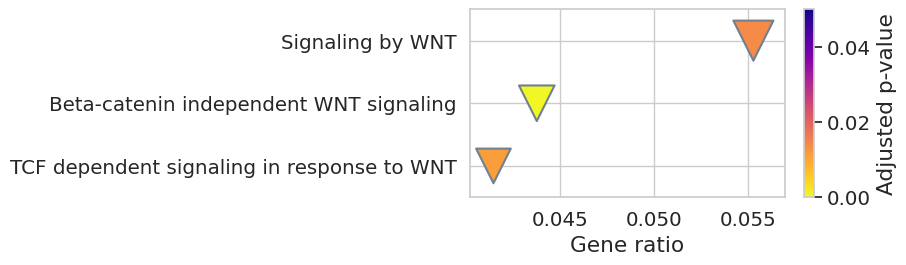

In [7]:
plotting = plotting.sort_values('GeneRatio', ascending = False)
sns.set_style("whitegrid")
sns.set(font_scale = 1.3, style = "whitegrid")

# Normalize p.adjust values
norm = mcolors.Normalize(vmin=0, vmax=0.05)
cmap = cm.plasma_r
colors = [cmap(norm(val)) for val in plotting["p.adjust"]]

# Scale GeneRatio for triangle size
size_scale = 15000
sizes = plotting["GeneRatio"] * size_scale

# Create the plot
fig, ax = plt.subplots(figsize=(9, 3))
# Expand borders to fit triangles
ax.set_ylim(-0.5, len(plotting["Description"]) - 0.5)
ax.set_xlim(plotting["GeneRatio"].min() * 0.97, plotting["GeneRatio"].max() * 1.03)

# Actually plot
sns.scatterplot(
    x=plotting["GeneRatio"],
    y=plotting["Description"],
    s=sizes,
    marker="v",  # downward-facing triangle
    color=colors,  # prevent default fill
    edgecolor='slategrey',
    linewidth=1.5,
    ax=ax
)

# Add colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Adjusted p-value")

# Fix labels
ax.set_xlabel("Gene ratio")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig('../../plots/05_validation_oligos/WNT_paths_oligos.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [26]:
gene_list = ['Gene list','Oligodendrocyte maturation']
padj = ['padj', '0.0145219847']
nes = ['NES', '-1.687538']

# Extract column names and data
columns = [gene_list[0], padj[0], nes[0]]
data = list(zip(gene_list[1:], padj[1:], nes[1:]))

# Create DataFrame
df = pd.DataFrame(data, columns=columns)
df['padj'] = df['padj'].astype(float)
df['NES'] = df['NES'].astype(float)
print(df)

                    Gene list      padj       NES
0  Oligodendrocyte maturation  0.014522 -1.687538


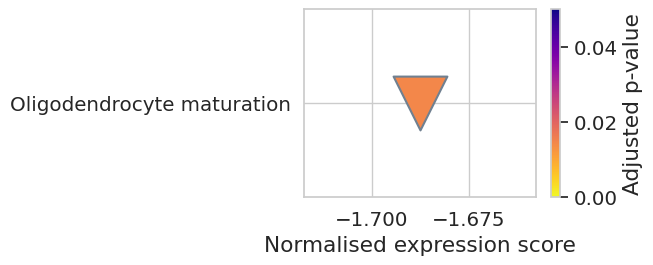

In [31]:
df = df.sort_values('NES', ascending = False)
sns.set_style("whitegrid")
sns.set(font_scale = 1.3, style = "whitegrid")

# Normalize p.adjust values
norm = mcolors.Normalize(vmin=0, vmax=0.05)
cmap = cm.plasma_r
colors = [cmap(norm(val)) for val in df["padj"]]

# Scale GeneRatio for triangle size
#size_scale = 15000
#sizes = [1,1] * size_scale

# Create the plot
fig, ax = plt.subplots(figsize=(6.5, 3))
# Expand borders to fit triangles
ax.set_ylim(-0.5, len(df["Gene list"]) - 0.5)
ax.set_xlim(df["NES"].min()-0.03, df["NES"].max()+0.03)

# Actually plot
sns.scatterplot(
    x=df["NES"],
    y=df["Gene list"],
    s=1500,
    marker="v",  # downward-facing triangle
    c=colors,  # prevent default fill
    edgecolor='slategrey',
    linewidth=1.5,
    ax=ax
)

# Add colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Adjusted p-value")

# Fix labels
ax.set_xlabel("Normalised expression score")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig('../../plots/05_validation_oligos/bulk_pathways_all_regions.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [11]:
gene_list = ['Symbol', 'NEAT1']
padj = ['padj', '0.000794']
nes = ['logFC', '0.578']

# Extract column names and data
columns = [gene_list[0], padj[0], nes[0]]
data = list(zip(gene_list[1:], padj[1:], nes[1:]))

# Create DataFrame
df = pd.DataFrame(data, columns=columns)
df['padj'] = df['padj'].astype(float)
df['logFC'] = df['logFC'].astype(float)
print(df)

  Symbol      padj  logFC
0  NEAT1  0.000794  0.578


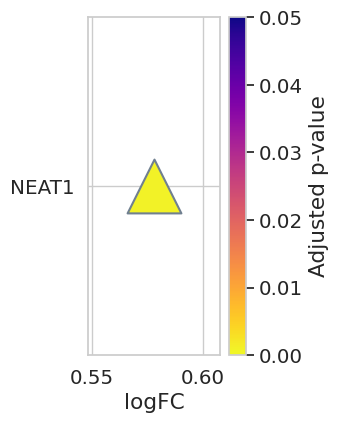

In [25]:
df = df.sort_values('logFC', ascending = False)
sns.set_style("whitegrid")
sns.set(font_scale = 1.3, style = "whitegrid")

# Normalize p.adjust values
norm = mcolors.Normalize(vmin=0, vmax=0.05)
cmap = cm.plasma_r
#colors = [cmap(norm(val)) for val in df["padj"]]

# Scale GeneRatio for triangle size
#size_scale = 15000
#sizes = [1,1] * size_scale

# Create the plot
fig, ax = plt.subplots(figsize=(3.5, 4.5))
# Expand borders to fit triangles
ax.set_ylim(-0.5, len(df["Symbol"]) - 0.5)
ax.set_xlim(df["logFC"].min()-0.03, df["logFC"].max()+0.03)

# Actually plot
sns.scatterplot(
    x=df["logFC"],
    y=df["Symbol"],
    s=1500,
    marker="^",  # downward-facing triangle
    c=colors,  # prevent default fill
    edgecolor='slategrey',
    linewidth=1.5,
    ax=ax
)

# Add colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Adjusted p-value")

# Fix labels
ax.set_xlabel("logFC")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig('../../plots/05_validation_oligos/NEAT1_all_regions.png', dpi = 300, bbox_inches = 'tight')
plt.show()

  Symbol  padj  logFC
0   PI3P  0.03  0.578


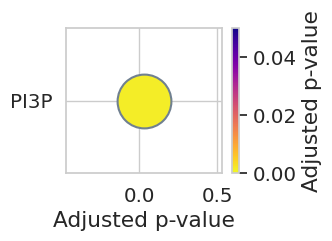

In [36]:
gene_list = ['Symbol', 'PI3P']
padj = ['padj', '0.030']
nes = ['logFC', '0.578']

# Extract column names and data
columns = [gene_list[0], padj[0], nes[0]]
data = list(zip(gene_list[1:], padj[1:], nes[1:]))

# Create DataFrame
df = pd.DataFrame(data, columns=columns)
df['padj'] = df['padj'].astype(float)
df['logFC'] = df['logFC'].astype(float)
print(df)

df = df.sort_values('logFC', ascending = False)
sns.set_style("whitegrid")
sns.set(font_scale = 1.3, style = "whitegrid")

# Normalize p.adjust values
norm = mcolors.Normalize(vmin=0, vmax=0.05)
cmap = cm.plasma_r
#colors = [cmap(norm(val)) for val in df["padj"]]

# Scale GeneRatio for triangle size
size_scale = 1500
sizes = 1 * size_scale

# Create the plot
fig, ax = plt.subplots(figsize=(3.5, 2.5))
# Expand borders to fit triangles
ax.set_ylim(-0.25, len(df["Symbol"]) - 0.75)
ax.set_xlim(df["padj"].min()-0.5, df["padj"].max()+0.5)

# Actually plot
sns.scatterplot(
    x=df["padj"],
    y=df["Symbol"],
    s=sizes,
    marker="o",  # downward-facing triangle
    hue = df["padj"],
    hue_norm = (0,1),
    palette = 'plasma_r',
    edgecolor='slategrey',
    linewidth=1.5,
    ax=ax
)

# Add colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Adjusted p-value")

# Fix labels
ax.set_xlabel("Adjusted p-value")
ax.set_ylabel("")
ax.legend_.remove()
plt.tight_layout()
plt.savefig('../../plots/05_validation_oligos/PI3P_ACG.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [ ]:
sns.set(font_scale = 1.3, style = "whitegrid")

plotting = df_mat[df_mat['tissue']=='F']
plotting = plotting[plotting['direction']=='Down-regulated']
#plotting = filtered_OGs[filtered_OGs['annot_level']==1]

sns.set_style("whitegrid")

# Normalize p.adjust values
norm = mcolors.Normalize(vmin=0, vmax=1)
cmap = cm.plasma_r

# Scale GeneRatio for triangle size
size_scale = 1500
sizes = 1 * size_scale

# Create the plot
fig, ax = plt.subplots(figsize=(8, 4))
# Expand borders to fit triangles
#ax.set_ylim(-1, len(plotting["p_adjust"]) - 1)
#ax.set_xlim(4 * 0.87, 4 * 1.04)
ax.margins(x=0.1, y=0.2)  # 5% extra space on each side
# Actually plot
sns.scatterplot(
    x=plotting["p_adjust"],
    y=plotting["assay"],
    s=sizes,
    marker="v",  # downward-facing triangle
    hue = plotting["p_adjust"],
    hue_norm = (0,1),
    palette = 'plasma_r',
    edgecolor='slategrey',
    linewidth=1.5,
    ax=ax
)

# Add colorbar
sm = cm.ScalarMappable(cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Adjusted p-value")

# Fix labels
ax.set_xlabel("FDR-adjusted p-value")
ax.set_ylabel("")
ax.legend_.remove()
plt.tight_layout()
plt.savefig('../../plots/08_transcriptomics/srnaseq_oligo_maturation.png', dpi = 300, bbox_inches = 'tight')
plt.show()